# TFM – Construcción de la matriz final para clustering

Notebook reproducible para preparar la matriz definitiva de clustering a partir de la base candidata validada, incorporando la deflactación de ingresos por IPC Nacional – Nivel General y dejando lista la etapa posterior de análisis sin ejecutar aún ningún algoritmo de clustering.

**Objetivo general**

1. Cargar la base candidata validada.
2. Procesar la serie de IPC de forma robusta.
3. Construir `P21_real` y `log_P21_real`.
4. Auditar los ingresos y la matriz final.
5. Exportar la base definitiva y los reportes auxiliares.

**Restricciones metodológicas**

- No se reconstruyen `CAES`, `TAM_EST` ni `INTENSI`.
- No se vuelven a utilizar `PP04B_COD`, `PP04C` ni `PP04C99`.
- No se aplica `winsorización`, truncamiento ni tratamiento de outliers.
- No se utiliza `P47T`.
- No se ejecuta todavía ningún método de clustering.

## 00. Configuración del entorno

En esta sección se cargan las librerías necesarias, se definen las rutas del proyecto con `Path` y se crea la carpeta de salida si no existe. Esta preparación asegura que el notebook sea reproducible y que los resultados queden guardados de forma ordenada en el directorio del TFM.

In [14]:
from pathlib import Path
import unicodedata
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")

def resolver_directorio_proyecto():
    marcadores = {"TFM_proyecto.Rproj", "README.txt", "Datos", "Salidas", "Scripts R"}
    candidatos = [Path.cwd(), *Path.cwd().parents]
    for candidato in candidatos:
        if (candidato / "TFM_proyecto.Rproj").exists():
            return candidato
        if sum((candidato / marcador).exists() for marcador in marcadores) >= 3:
            return candidato
    raise FileNotFoundError("No se pudo detectar el directorio raíz del proyecto. Abra el notebook dentro de la carpeta del TFM.")

PROJECT_DIR = resolver_directorio_proyecto()
OUTPUT_DIR = PROJECT_DIR / "Salidas" / "07_clustering"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_CANDIDATE_PARQUET = OUTPUT_DIR / "base_clustering_candidata.parquet"
BASE_CANDIDATE_CSV = OUTPUT_DIR / "base_clustering_candidata.csv"


def normalizar_texto(valor):
    if pd.isna(valor):
        return ""
    texto = str(valor).strip().lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    return texto


def buscar_archivo(raiz, nombre_exacto=None, patrones=None):
    raiz = Path(raiz)
    if nombre_exacto:
        candidatos = list(raiz.rglob(nombre_exacto))
        if candidatos:
            return candidatos[0]
    if patrones:
        for patron in patrones:
            candidatos = list(raiz.rglob(patron))
            if candidatos:
                return candidatos[0]
    return None


def cargar_base_candidata():
    if BASE_CANDIDATE_PARQUET.exists():
        return pd.read_parquet(BASE_CANDIDATE_PARQUET), BASE_CANDIDATE_PARQUET
    if BASE_CANDIDATE_CSV.exists():
        return pd.read_csv(BASE_CANDIDATE_CSV), BASE_CANDIDATE_CSV
    raise FileNotFoundError("No se encontró la base_clustering_candidata en parquet ni en CSV.")


print(f"Directorio del proyecto: {PROJECT_DIR}")
print(f"Directorio de salida: {OUTPUT_DIR}")

Directorio del proyecto: c:\Users\tomas\OneDrive\Master Granada\TFM
Directorio de salida: c:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering


## 01. Carga de datos

Se parte de la base candidata ya validada, que contiene las variables estructurales necesarias para la matriz final de clustering. El objetivo de esta sección es cargar la base desde parquet con fallback a CSV, verificar su estructura y documentar el número de observaciones y variables disponibles.

In [2]:
df, base_candidata_path = cargar_base_candidata()

print(f"Archivo de entrada utilizado: {base_candidata_path}")
print(f"Número de observaciones: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}")

display(df.head())
df.info()

Archivo de entrada utilizado: C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\base_clustering_candidata.parquet
Número de observaciones: 80300
Número de variables: 17


,id_persona,CODUSU,NRO_HOGAR,COMPONENTE,ANO4,TRIMESTRE,CH04,CH06,NIVEL_ED,REGION,CAT_OCUP,CAES,TAM_EST,INTENSI,P21,PONDERA,PP04B_COD
0,TQRMNOSQYHJMLPCDEIKAH00793199_1_1,TQRMNOSQYHJMLPCDEIKAH00793199,1,1,2024,1,1,68,2,43,2,6.0,1,Subocupado,150000,648,4000
1,TQRMNOTQRHJMLOCDEHJGH00794657_1_1,TQRMNOTQRHJMLOCDEHJGH00794657,1,1,2024,1,2,41,4,40,2,19.0,1,Ocupado pleno,250000,252,9602
2,TQRMNORXSHJMLQCDEGPDJ00794708_1_2,TQRMNORXSHJMLQCDEGPDJ00794708,1,2,2024,1,2,31,4,40,2,19.0,1,Subocupado,50000,193,9602
3,TQRMNORWUHJKKSCDEHGHJ00794732_1_2,TQRMNORWUHJKKSCDEHGHJ00794732,1,2,2024,1,2,44,4,44,4,9.0,6-25,Ocupado pleno,0,215,5601
4,TQRMNOPRYHJNLUCDEIJAH00796094_1_1,TQRMNOPRYHJNLUCDEIJAH00796094,1,1,2024,1,2,38,3,1,3,20.0,No aplica,Ocupado pleno,400000,2564,9700


<class 'pandas.DataFrame'>
RangeIndex: 80300 entries, 0 to 80299
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id_persona  80300 non-null  str     
 1   CODUSU      80300 non-null  str     
 2   NRO_HOGAR   80300 non-null  str     
 3   COMPONENTE  80300 non-null  str     
 4   ANO4        80300 non-null  str     
 5   TRIMESTRE   80300 non-null  str     
 6   CH04        80300 non-null  str     
 7   CH06        80300 non-null  str     
 8   NIVEL_ED    80300 non-null  str     
 9   REGION      80300 non-null  str     
 10  CAT_OCUP    80300 non-null  str     
 11  CAES        79751 non-null  float64 
 12  TAM_EST     80300 non-null  str     
 13  INTENSI     80300 non-null  category
 14  P21         80300 non-null  str     
 15  PONDERA     80300 non-null  str     
 16  PP04B_COD   80300 non-null  str     
dtypes: category(1), float64(1), str(15)
memory usage: 16.9 MB


## 02. Procesamiento del IPC

En un contexto inflacionario, los ingresos nominales observados en distintos trimestres no son directamente comparables porque una misma suma monetaria representa distinto poder adquisitivo a lo largo del tiempo. Por eso se deflacta `P21` con IPC Nacional – Nivel General, de modo que la comparación temporal se haga en términos reales y no monetarios.

In [3]:
ipc_path = buscar_archivo(
    PROJECT_DIR,
    nombre_exacto="serie_ipc_divisiones.csv",
    patrones=["*serie_ipc_divisiones.csv", "*ipc*divisiones*.csv", "*ipc*.csv"],
)

if ipc_path is None:
    raise FileNotFoundError("No se localizó serie_ipc_divisiones.csv ni un archivo equivalente dentro del proyecto.")

try:
    ipc_raw = pd.read_csv(ipc_path, sep=";", encoding="latin-1")
except Exception:
    ipc_raw = pd.read_csv(ipc_path, sep=None, engine="python", encoding="latin-1")

ipc_raw.columns = [normalizar_texto(col).replace(" ", "_") for col in ipc_raw.columns]


def elegir_columna(columns, candidatos, obligatoria=True):
    columnas_normalizadas = {normalizar_texto(col).replace(" ", "_"): col for col in columns}
    for candidato in candidatos:
        candidato_norm = normalizar_texto(candidato).replace(" ", "_")
        for nombre_norm, nombre_original in columnas_normalizadas.items():
            if candidato_norm == nombre_norm or candidato_norm in nombre_norm:
                return nombre_original
    if obligatoria:
        raise KeyError(f"No se encontró ninguna de las columnas esperadas: {candidatos}")
    return None


col_codigo = elegir_columna(ipc_raw.columns, ["codigo", "cod", "id"], obligatoria=False)
col_periodo = elegir_columna(ipc_raw.columns, ["periodo", "fecha", "anio_mes"])
col_indice = elegir_columna(ipc_raw.columns, ["indice_ipc", "ipc", "indice"])
col_descripcion = elegir_columna(ipc_raw.columns, ["descripcion", "desc", "serie"], obligatoria=False)
col_clasificador = elegir_columna(ipc_raw.columns, ["clasificador"], obligatoria=False)
col_region = elegir_columna(ipc_raw.columns, ["region", "ambito"], obligatoria=False)

ipc_filtrado = ipc_raw.copy()

mascara_nivel_general = pd.Series(False, index=ipc_filtrado.index)
if col_descripcion is not None:
    mascara_nivel_general = mascara_nivel_general | (
        ipc_filtrado[col_descripcion].astype(str).map(normalizar_texto).eq("nivel general")
    )
if col_codigo is not None:
    mascara_nivel_general = mascara_nivel_general | (
        pd.to_numeric(ipc_filtrado[col_codigo], errors="coerce").eq(0)
    )

if col_region is not None:
    mascara_region = ipc_filtrado[col_region].astype(str).map(normalizar_texto).eq("nacional")
else:
    mascara_region = pd.Series(True, index=ipc_filtrado.index)

ipc_filtrado = ipc_filtrado[mascara_nivel_general & mascara_region].copy()

ipc_filtrado["ipc_valor"] = pd.to_numeric(
    ipc_filtrado[col_indice].astype(str).str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)
ipc_filtrado["fecha"] = pd.to_datetime(ipc_filtrado[col_periodo].astype(str).str.zfill(6), format="%Y%m", errors="coerce")
ipc_filtrado = ipc_filtrado.dropna(subset=["fecha", "ipc_valor"]).sort_values("fecha").copy()
ipc_filtrado["ANO4"] = ipc_filtrado["fecha"].dt.year.astype(int)
ipc_filtrado["TRIMESTRE"] = ((ipc_filtrado["fecha"].dt.month - 1) // 3 + 1).astype(int)

ipc_trimestral = (
    ipc_filtrado.groupby(["ANO4", "TRIMESTRE"], as_index=False)
    .agg(
        ipc_promedio_trimestre=("ipc_valor", "mean"),
        observaciones=("ipc_valor", "size"),
        fecha_inicio=("fecha", "min"),
        fecha_fin=("fecha", "max"),
    )
    .sort_values(["ANO4", "TRIMESTRE"])
    .reset_index(drop=True)
)

trimestre_base = (2025, 4)
if not ((ipc_trimestral["ANO4"].eq(trimestre_base[0])) & (ipc_trimestral["TRIMESTRE"].eq(trimestre_base[1]))).any():
    raise ValueError("No se encontró 2025T4 en la serie IPC filtrada; no se puede fijar esa base.")

ipc_base = ipc_trimestral.loc[
    (ipc_trimestral["ANO4"].eq(trimestre_base[0])) & (ipc_trimestral["TRIMESTRE"].eq(trimestre_base[1])),
    "ipc_promedio_trimestre",
].iloc[0]
ipc_trimestral["coeficiente_deflactor"] = ipc_base / ipc_trimestral["ipc_promedio_trimestre"]

print(f"Archivo IPC utilizado: {ipc_path}")
print(f"Observaciones IPC nivel general nacional: {len(ipc_filtrado)}")
print(f"Trimestre base utilizado: {trimestre_base[0]}T{trimestre_base[1]}")
display(ipc_trimestral.tail())

Archivo IPC utilizado: C:\Users\tomas\OneDrive\Master Granada\TFM\Datos\serie_ipc_divisiones.csv
Observaciones IPC nivel general nacional: 115
Trimestre base utilizado: 2025T4


,ANO4,TRIMESTRE,ipc_promedio_trimestre,observaciones,fecha_inicio,fecha_fin,coeficiente_deflactor
34,2025,2,8718.554333,3,2025-04-01,2025-06-01,1.130409
35,2025,3,9200.436433,3,2025-07-01,2025-09-01,1.071203
36,2025,4,9855.530633,3,2025-10-01,2025-12-01,1.000000
37,2026,1,10734.905733,3,2026-01-01,2026-03-01,0.918083
38,2026,2,11598.964800,3,2026-04-01,2026-06-01,0.849691


## 03. Construcción de ingresos reales

El ingreso real permite expresar `P21` en términos de poder adquisitivo comparable entre trimestres. La transformación logarítmica con `np.log1p` reduce la asimetría típica de las distribuciones de ingresos, atenúa la influencia de valores extremos y conserva los ceros sin introducir transformaciones arbitrarias.

In [4]:
df = df.copy()
df["ANO4"] = pd.to_numeric(df["ANO4"], errors="coerce").astype("Int64")
df["TRIMESTRE"] = pd.to_numeric(df["TRIMESTRE"], errors="coerce").astype("Int64")
df["CH06"] = pd.to_numeric(df["CH06"], errors="coerce")
df["PONDERA"] = pd.to_numeric(df["PONDERA"], errors="coerce")

df = df.drop(columns=["coeficiente_deflactor"], errors="ignore")
df = df.merge(ipc_trimestral[["ANO4", "TRIMESTRE", "coeficiente_deflactor"]], on=["ANO4", "TRIMESTRE"], how="left")

df["P21"] = pd.to_numeric(df["P21"], errors="coerce").replace(-9, np.nan)
df["P21_real"] = df["P21"] * df["coeficiente_deflactor"]
df["log_P21_real"] = np.log1p(df["P21_real"])

display(df[["id_persona", "ANO4", "TRIMESTRE", "P21", "coeficiente_deflactor", "P21_real", "log_P21_real"]].head(10))

,id_persona,ANO4,TRIMESTRE,P21,coeficiente_deflactor,P21_real,log_P21_real
0,TQRMNOSQYHJMLPCDEIKAH00793199_1_1,2024,1,150000.0,2.046922,307038.345012,12.634731
1,TQRMNOTQRHJMLOCDEHJGH00794657_1_1,2024,1,250000.0,2.046922,511730.575019,13.145555
2,TQRMNORXSHJMLQCDEGPDJ00794708_1_2,2024,1,50000.0,2.046922,102346.115004,11.536125
3,TQRMNORWUHJKKSCDEHGHJ00794732_1_2,2024,1,0.0,2.046922,0.000000,0.000000
4,TQRMNOPRYHJNLUCDEIJAH00796094_1_1,2024,1,400000.0,2.046922,818768.920031,13.615558
5,TQRMNOSRUHJOMLCDEHPJB00796113_1_3,2024,1,80000.0,2.046922,163753.784006,12.006125
6,TQRMNOSRUHJOMLCDEHPJB00796113_1_1,2024,1,160000.0,2.046922,327507.568012,12.699269
7,TQRMNOPSWHJOLMCDEHIBB00796139_1_3,2024,1,48000.0,2.046922,98252.270404,11.495304
8,TQRMNOQWQHJMKMCDEHMHF00796152_1_1,2024,1,400000.0,2.046922,818768.920031,13.615558
9,TQRMNOQSQHJOKPCDEGLDF00794422_1_3,2024,1,165000.0,2.046922,337742.179513,12.730041


## 04. Auditoría de ingresos

Esta sección evalúa la calidad de `P21`, `P21_real` y `log_P21_real` mediante conteos de valores válidos y faltantes, estadísticos descriptivos y visualizaciones. El objetivo es documentar la distribución del ingreso transformado sin aplicar ningún tratamiento de recorte o limpieza artificial.

In [5]:
def resumir_variables(df_base, variables):
    resumen = []
    for variable in variables:
        serie = df_base[variable]
        n_total = len(serie)
        n_na = int(serie.isna().sum())
        resumen.append({
            "Variable": variable,
            "N": int(serie.notna().sum()),
            "NA": n_na,
            "%NA": round((n_na / n_total) * 100, 2) if n_total else np.nan,
        })
    return pd.DataFrame(resumen)


def resumir_descriptivos(serie):
    serie_valida = pd.to_numeric(serie, errors="coerce")
    return pd.Series({
        "media": serie_valida.mean(),
        "mediana": serie_valida.median(),
        "desvio_estandar": serie_valida.std(),
        "minimo": serie_valida.min(),
        "p25": serie_valida.quantile(0.25),
        "p75": serie_valida.quantile(0.75),
        "p95": serie_valida.quantile(0.95),
        "maximo": serie_valida.max(),
    })

auditoria_ingresos = resumir_variables(df, ["P21", "P21_real", "log_P21_real"])
descriptivos_ingresos = pd.DataFrame({
    variable: resumir_descriptivos(df[variable])
    for variable in ["P21", "P21_real", "log_P21_real"]
}).T

auditoria_ingresos.to_csv(OUTPUT_DIR / "auditoria_ingresos.csv", index=False)
descriptivos_ingresos.to_csv(OUTPUT_DIR / "descriptivos_ingresos.csv")

display(auditoria_ingresos)
display(descriptivos_ingresos)

,Variable,N,NA,%NA
0,P21,66311,13989,17.42
1,P21_real,66311,13989,17.42
2,log_P21_real,66311,13989,17.42


,media,mediana,desvio_estandar,minimo,p25,p75,p95,maximo
P21,314987.010511,200000.000000,352335.637292,0.0,100000.000000,400000.000000,9.000000e+05,1.147000e+07
P21_real,423593.348861,334254.686662,420644.096542,0.0,169561.321577,559391.148470,1.068926e+06,1.296579e+07
log_P21_real,12.108824,12.719662,2.742441,0.0,12.040976,13.234606,1.388217e+01,1.637782e+01


In [17]:
pd.crosstab(
    df["CAT_OCUP"],
    df["P21"].isna(),
    normalize="index"
) * 100




P21,False,True
CAT_OCUP,,
1,81.207675,18.792325
2,79.316693,20.683307
3,84.218605,15.781395
4,100.000000,0.000000


In [18]:
df["P21"].isna().mean()

np.float64(0.17420921544209214)

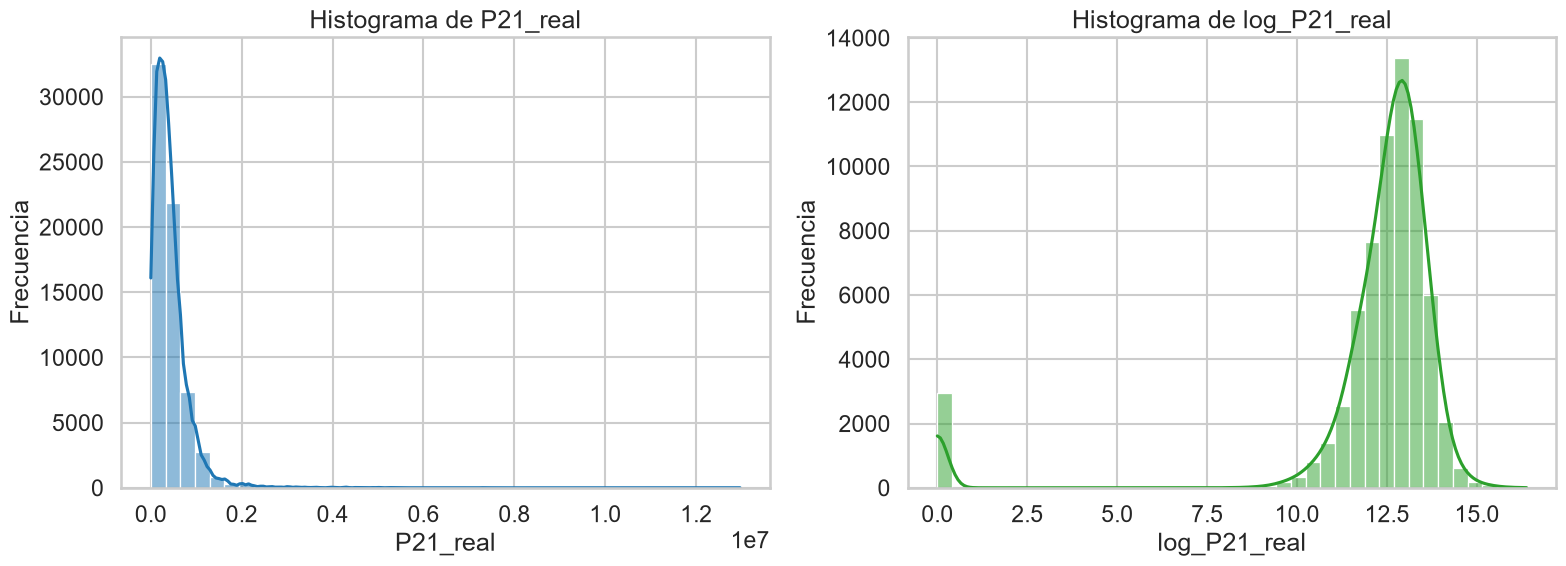

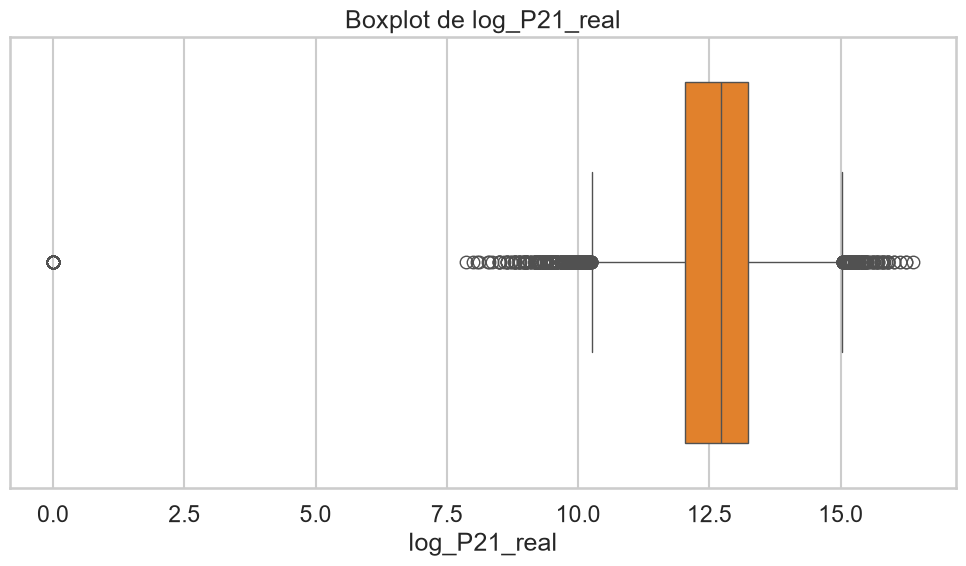

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df["P21_real"].dropna(), bins=40, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Histograma de P21_real")
axes[0].set_xlabel("P21_real")
axes[0].set_ylabel("Frecuencia")

sns.histplot(df["log_P21_real"].dropna(), bins=40, kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title("Histograma de log_P21_real")
axes[1].set_xlabel("log_P21_real")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "histogramas_ingresos.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x=df["log_P21_real"], color="#ff7f0e")
plt.title("Boxplot de log_P21_real")
plt.xlabel("log_P21_real")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "boxplot_log_P21_real.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
auditoria_na_cat_ocup = (
    df.groupby("CAT_OCUP")["P21"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
    .reset_index(name="%NA_P21")
)

auditoria_na_intensi = (
    df.groupby("INTENSI")["P21"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
    .reset_index(name="%NA_P21")
)

print("% de NA en P21 por CAT_OCUP")
display(auditoria_na_cat_ocup)
print("% de NA en P21 por INTENSI")
display(auditoria_na_intensi)

% de NA en P21 por CAT_OCUP


,CAT_OCUP,%NA_P21
0,1,18.79
1,2,20.68
2,3,15.78
3,4,0.00


% de NA en P21 por INTENSI


,INTENSI,%NA_P21
0,Subocupado,16.94
1,Ocupado pleno,17.17
2,Sobreocupado,18.35
3,No trabajó,17.12


## 05. Comparación temporal

Esta sección evalúa el efecto de la deflactación comparando, por trimestre, la mediana de `P21` y la mediana de `P21_real`. La diferencia entre ambas series permite visualizar cuánto cambia la lectura temporal del ingreso cuando se controla por inflación.

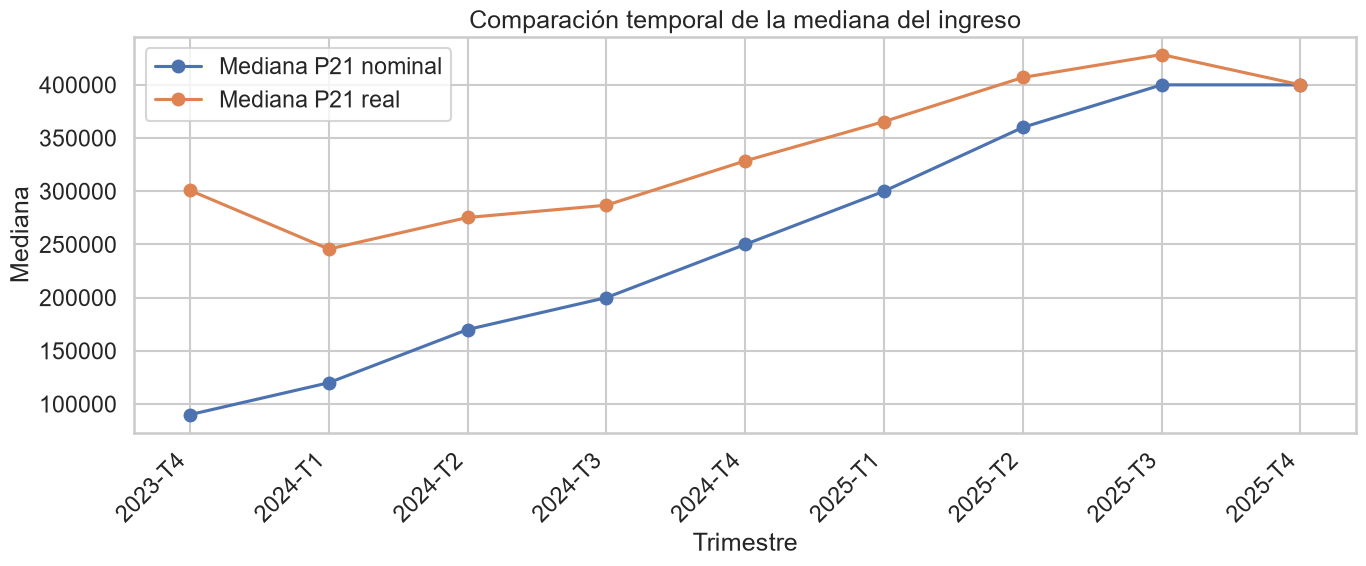

,ANO4,TRIMESTRE,mediana_P21,mediana_P21_real,Periodo
4,2024,4,250000.0,328526.557995,2024-T4
5,2025,1,300000.0,365464.313366,2025-T1
6,2025,2,360000.0,406947.171785,2025-T2
7,2025,3,400000.0,428481.005428,2025-T3
8,2025,4,400000.0,400000.000000,2025-T4


In [7]:
comparacion_trimestral = (
    df.groupby(["ANO4", "TRIMESTRE"], as_index=False)
    .agg(
        mediana_P21=("P21", "median"),
        mediana_P21_real=("P21_real", "median"),
    )
    .sort_values(["ANO4", "TRIMESTRE"])
    .reset_index(drop=True)
)

comparacion_trimestral["Periodo"] = comparacion_trimestral["ANO4"].astype(str) + "-T" + comparacion_trimestral["TRIMESTRE"].astype(str)

plt.figure(figsize=(14, 6))
plt.plot(comparacion_trimestral["Periodo"], comparacion_trimestral["mediana_P21"], marker="o", label="Mediana P21 nominal")
plt.plot(comparacion_trimestral["Periodo"], comparacion_trimestral["mediana_P21_real"], marker="o", label="Mediana P21 real")
plt.xticks(rotation=45, ha="right")
plt.title("Comparación temporal de la mediana del ingreso")
plt.xlabel("Trimestre")
plt.ylabel("Mediana")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparacion_temporal_mediana_ingresos.png", dpi=300, bbox_inches="tight")
plt.show()

display(comparacion_trimestral.tail())

## 06. Construcción de la matriz final para clustering

La matriz final conserva únicamente las variables que serán insumo para la etapa posterior de clustering. En particular, `log_P21_real` se incorpora como la variable económica definitiva, mientras que `P21`, `P21_real` y `PP04B_COD` quedan fuera de la versión final para evitar redundancias y mantener la base alineada con las decisiones metodológicas ya cerradas.

In [12]:
columnas_finales = [
    "id_persona",
    "ANO4",
    "TRIMESTRE",
    "CH04",
    "CH06",
    "NIVEL_ED",
    "REGION",
    "CAT_OCUP",
    "CAES",
    "TAM_EST",
    "INTENSI",
    "log_P21_real",
    "PONDERA",
]

base_clustering_final = df[columnas_finales].copy()

for columna in ["P21", "P21_real", "PP04B_COD"]:
    if columna in base_clustering_final.columns:
        base_clustering_final = base_clustering_final.drop(columns=[columna])

for columna in ["CH04", "NIVEL_ED", "REGION", "CAT_OCUP", "CAES", "TAM_EST", "INTENSI"]:
    base_clustering_final[columna] = base_clustering_final[columna].astype("category")

base_clustering_final["CH06"] = pd.to_numeric(base_clustering_final["CH06"], errors="coerce")
base_clustering_final["PONDERA"] = pd.to_numeric(base_clustering_final["PONDERA"], errors="coerce")

print(base_clustering_final.dtypes)
display(base_clustering_final.head())
print(base_clustering_final.shape)

id_persona           str
ANO4               Int64
TRIMESTRE          Int64
CH04            category
CH06               int64
NIVEL_ED        category
REGION          category
CAT_OCUP        category
CAES            category
TAM_EST         category
INTENSI         category
log_P21_real     float64
PONDERA            int64
dtype: object


,id_persona,ANO4,TRIMESTRE,CH04,CH06,NIVEL_ED,REGION,CAT_OCUP,CAES,TAM_EST,INTENSI,log_P21_real,PONDERA
0,TQRMNOSQYHJMLPCDEIKAH00793199_1_1,2024,1,1,68,2,43,2,6.0,1,Subocupado,12.634731,648
1,TQRMNOTQRHJMLOCDEHJGH00794657_1_1,2024,1,2,41,4,40,2,19.0,1,Ocupado pleno,13.145555,252
2,TQRMNORXSHJMLQCDEGPDJ00794708_1_2,2024,1,2,31,4,40,2,19.0,1,Subocupado,11.536125,193
3,TQRMNORWUHJKKSCDEHGHJ00794732_1_2,2024,1,2,44,4,44,4,9.0,6-25,Ocupado pleno,0.000000,215
4,TQRMNOPRYHJNLUCDEIJAH00796094_1_1,2024,1,2,38,3,1,3,20.0,No aplica,Ocupado pleno,13.615558,2564


(80300, 13)


## 07. Auditoría final de la matriz

Antes de exportar la base definitiva, se documenta la calidad de todas las variables finales mediante una tabla de auditoría general y frecuencias para las variables categóricas seleccionadas. Las categorías de baja frecuencia se marcan como menores al 1% sin recodificar la base.

In [9]:
auditoria_matriz_final = resumir_variables(base_clustering_final, base_clustering_final.columns)
auditoria_matriz_final.to_csv(OUTPUT_DIR / "auditoria_matriz_final.csv", index=False)

display(auditoria_matriz_final)


def frecuencia_con_menor_1porc(serie):
    frecuencia = serie.astype("object").fillna("NA").value_counts(dropna=False).reset_index()
    frecuencia.columns = ["categoria", "frecuencia"]
    frecuencia["porcentaje"] = (frecuencia["frecuencia"] / frecuencia["frecuencia"].sum()) * 100
    frecuencia["<1%"] = np.where(frecuencia["porcentaje"] < 1, "<1%", "")
    return frecuencia

frecuencia_cat_ocup = frecuencia_con_menor_1porc(base_clustering_final["CAT_OCUP"])
frecuencia_caes = frecuencia_con_menor_1porc(base_clustering_final["CAES"])
frecuencia_tam_est = frecuencia_con_menor_1porc(base_clustering_final["TAM_EST"])
frecuencia_intensi = frecuencia_con_menor_1porc(base_clustering_final["INTENSI"])

frecuencia_cat_ocup.to_csv(OUTPUT_DIR / "frecuencia_cat_ocup.csv", index=False)
frecuencia_caes.to_csv(OUTPUT_DIR / "frecuencia_caes.csv", index=False)
frecuencia_tam_est.to_csv(OUTPUT_DIR / "frecuencia_tam_est.csv", index=False)
frecuencia_intensi.to_csv(OUTPUT_DIR / "frecuencia_intensi.csv", index=False)

display(frecuencia_cat_ocup.head())
display(frecuencia_caes.head())
display(frecuencia_tam_est.head())
display(frecuencia_intensi.head())

,Variable,N,NA,%NA
0,id_persona,80300,0,0.00
1,ANO4,80300,0,0.00
2,TRIMESTRE,80300,0,0.00
3,CH04,80300,0,0.00
4,CH06,80300,0,0.00
5,NIVEL_ED,80300,0,0.00
6,REGION,80300,0,0.00
7,CAT_OCUP,80300,0,0.00
8,CAES,79751,549,0.68
9,TAM_EST,80300,0,0.00


,categoria,frecuencia,porcentaje,<1%
0,3,49514,61.661270,
1,2,28245,35.174346,
2,1,1772,2.206725,
3,4,769,0.957659,<1%


,categoria,frecuencia,porcentaje,<1%
0,7.0,18189,22.651308,
1,6.0,13004,16.194271,
2,20.0,9962,12.405978,
3,3.0,7346,9.148194,
4,9.0,5514,6.866750,


,categoria,frecuencia,porcentaje,<1%
0,2-5,24359,30.334994,
1,1,23827,29.672478,
2,No aplica,9765,12.160648,
3,6-25,9115,11.351183,
4,NS/NR,8067,10.046077,


,categoria,frecuencia,porcentaje,<1%
0,Ocupado pleno,42590,53.038605,
1,Sobreocupado,20459,25.478207,
2,Subocupado,15937,19.846824,
3,No trabajó,1314,1.636364,


## 08. Exportación

La matriz final y los reportes auxiliares se guardan en la carpeta de salidas del proyecto para que la etapa de clustering posterior pueda utilizar una base ya preparada, auditada y reproducible.

In [13]:
base_clustering_final.to_parquet(OUTPUT_DIR / "base_clustering_final.parquet", index=False)
base_clustering_final.to_csv(OUTPUT_DIR / "base_clustering_final.csv", index=False)

print("Archivos exportados:")
print(OUTPUT_DIR / "base_clustering_final.parquet")
print(OUTPUT_DIR / "base_clustering_final.csv")
print(OUTPUT_DIR / "auditoria_ingresos.csv")
print(OUTPUT_DIR / "descriptivos_ingresos.csv")
print(OUTPUT_DIR / "auditoria_matriz_final.csv")
print(OUTPUT_DIR / "frecuencia_cat_ocup.csv")
print(OUTPUT_DIR / "frecuencia_caes.csv")
print(OUTPUT_DIR / "frecuencia_tam_est.csv")
print(OUTPUT_DIR / "frecuencia_intensi.csv")

Archivos exportados:
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\base_clustering_final.parquet
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\base_clustering_final.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\auditoria_ingresos.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\descriptivos_ingresos.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\auditoria_matriz_final.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\frecuencia_cat_ocup.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\frecuencia_caes.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\frecuencia_tam_est.csv
C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\frecuencia_intensi.csv


## Síntesis metodológica final

La variable log_P21_real presenta un 17,42% de observaciones faltantes, heredadas de la ausencia de información en P21. La auditoría mostró que dichos faltantes se distribuyen de manera relativamente homogénea entre categorías ocupacionales e intensidad laboral, por lo que no se identificó evidencia de concentración sistemática en un grupo específico. La decisión sobre su tratamiento se realizará en la etapa de construcción de la matriz definitiva para clustering.

In [19]:
(df["P21"] == -9).sum()

np.int64(0)

In [20]:
df["P21"].value_counts(dropna=False).head(20)


P21
NaN          13989
200000.0      5457
300000.0      4758
400000.0      4278
100000.0      3276
500000.0      2983
0.0           2942
150000.0      2732
600000.0      2587
250000.0      2120
80000.0       1902
120000.0      1898
800000.0      1722
180000.0      1357
350000.0      1348
50000.0       1313
60000.0       1312
700000.0      1198
1000000.0      936
160000.0       923
Name: count, dtype: int64

Con el objetivo de evaluar la naturaleza de estas ausencias, se realizó una auditoría de cobertura por categoría ocupacional (CAT_OCUP) y condición de intensidad laboral (INTENSI). Los resultados muestran que los porcentajes de valores faltantes se distribuyen de manera relativamente homogénea entre los distintos grupos analizados, sin evidencia de concentración en una categoría específica. En particular, los faltantes oscilan entre 15,8% y 20,7% según categoría ocupacional y entre 16,9% y 18,4% según intensidad laboral.
Adicionalmente, se verificó que los valores faltantes no corresponden a códigos especiales de no respuesta posteriormente transformados en valores perdidos (por ejemplo, -9), ya que dichos códigos no se encuentran presentes en la base utilizada. Asimismo, los ingresos nulos (P21 = 0) constituyen una categoría distinta y fueron preservados como observaciones válidas.
A partir de esta evidencia, no se identifican indicios de que la ausencia de ingresos esté asociada de manera sistemática a un segmento particular del mercado laboral informal. En consecuencia, los valores faltantes fueron conservados sin imputación durante la construcción de la matriz final. La estrategia definitiva para su tratamiento será evaluada en la etapa de estimación del clustering, en función de los requerimientos específicos del método seleccionado.